In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [3]:
df=pd.read_csv("heart.csv")
df.head()
print(df.shape)
df.info()
df.describe()

(1025, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [4]:
print(df.isnull().sum())      # missing values
print(df.duplicated().sum())  # duplicate rows

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
723


target
1    526
0    499
Name: count, dtype: int64


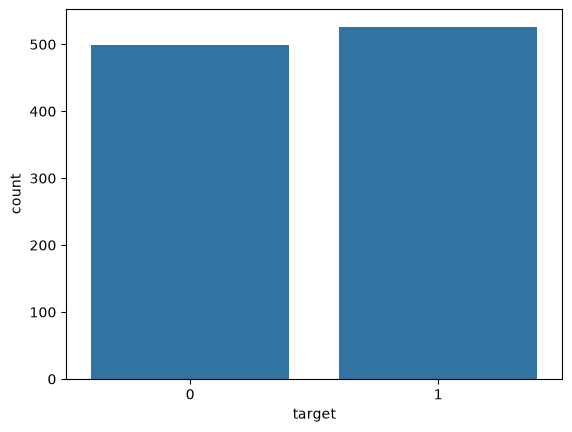

In [5]:
print(df["target"].value_counts())
sns.countplot(x="target", data=df)
plt.show()

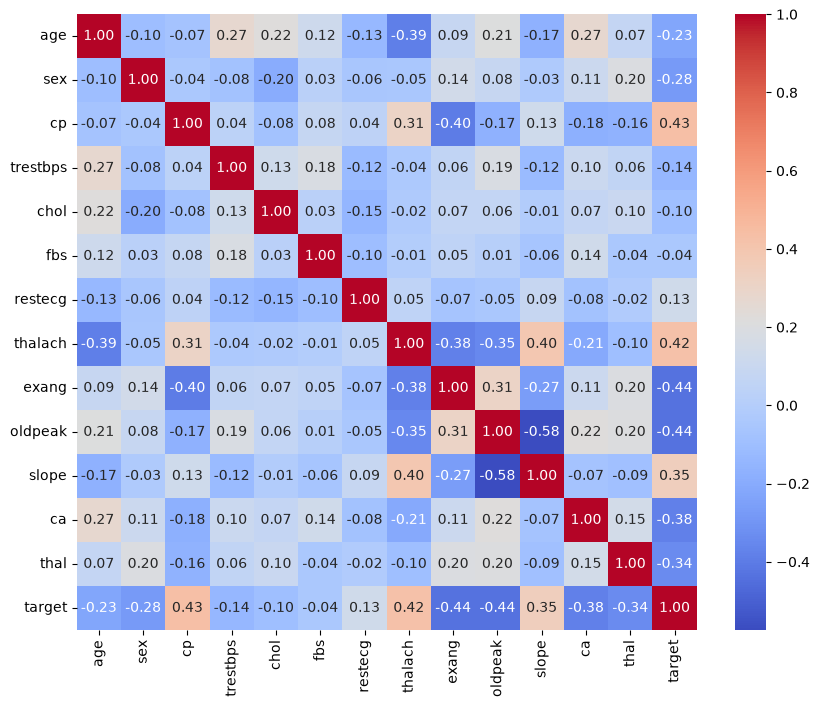

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)                     # (302, 14) aana chahiye
print(df["target"].value_counts())

(302, 14)
target
1    164
0    138
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)   # lagbhag (241, 13) aur (61, 13)

(241, 13) (61, 13)


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), continuous),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

pipe.fit(X_train, y_train)
print("Test accuracy:", pipe.score(X_test, y_test))
print("CV accuracy:", cross_val_score(pipe, X_train, y_train, cv=5).mean())

Test accuracy: 0.8360655737704918
CV accuracy: 0.8339285714285716


In [12]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
}

for name, model in models.items():
    p = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_val_score(p, X_train, y_train, cv=5)
    print(f"{name}: CV accuracy = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: CV accuracy = 0.834 (+/- 0.038)
KNN: CV accuracy = 0.838 (+/- 0.031)
Random Forest: CV accuracy = 0.842 (+/- 0.043)


In [13]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = pipe.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[23  5]
 [ 5 28]]
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        28
           1       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



In [14]:
print(df.groupby("target")[["age", "thalach", "oldpeak", "ca", "exang"]].mean())

              age     thalach   oldpeak        ca     exang
target                                                     
0       56.601449  139.101449  1.585507  1.166667  0.550725
1       52.585366  158.378049  0.586585  0.341463  0.140244


In [15]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import GridSearchCV

# class 0 (disease) ka recall naapne wala scorer
disease_recall = make_scorer(recall_score, pos_label=0)

# Logistic Regression
lr_pipe = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
lr_search = GridSearchCV(lr_pipe, {"model__C": [0.01, 0.1, 1, 10, 100]},
                         cv=5, scoring=disease_recall)
lr_search.fit(X_train, y_train)
print("LR best:", lr_search.best_params_, round(lr_search.best_score_, 3))

# Random Forest
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(random_state=42))])
rf_grid = {
    "model__n_estimators": [100, 300],
    "model__max_depth": [3, 5, None],
    "model__min_samples_leaf": [1, 3, 5],
}
rf_search = GridSearchCV(rf_pipe, rf_grid, cv=5, scoring=disease_recall)
rf_search.fit(X_train, y_train)
print("RF best:", rf_search.best_params_, round(rf_search.best_score_, 3))

LR best: {'model__C': 0.1} 0.8
RF best: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300} 0.791


In [16]:
for name, s in [("LR", lr_search), ("RF", rf_search)]:
    pred = s.predict(X_test)
    print(name)
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))

LR
[[23  5]
 [ 5 28]]
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        28
           1       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61

RF
[[23  5]
 [ 7 26]]
              precision    recall  f1-score   support

           0       0.77      0.82      0.79        28
           1       0.84      0.79      0.81        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61



In [17]:
final_model = lr_search.best_estimator_

print(final_model.classes_)   # [0 1] aana chahiye
# classes_ = [0, 1], is liye proba[:, 0] = disease (class 0) ki probability
proba = final_model.predict_proba(X_test)
p_disease = proba[:, 0]

def safety_layer(p, high=0.60, low=0.20):
    if p >= high:
        return "High risk - consult a doctor"
    elif p <= low:
        return "Low risk"
    else:
        return "Uncertain - consult a doctor"

results = pd.DataFrame({
    "p_disease": p_disease.round(2),
    "actual": y_test.values,           # 0 = disease, 1 = healthy
    "decision": [safety_layer(p) for p in p_disease],
})

print(results["decision"].value_counts())
print(pd.crosstab(results["decision"], results["actual"]))

[0 1]
decision
High risk - consult a doctor    24
Uncertain - consult a doctor    20
Low risk                        17
Name: count, dtype: int64
actual                         0   1
decision                            
High risk - consult a doctor  20   4
Low risk                       1  16
Uncertain - consult a doctor   7  13


In [18]:
new_patient = pd.DataFrame([{
    "age": 58, "sex": 1, "cp": 0, "trestbps": 140, "chol": 240,
    "fbs": 0, "restecg": 1, "thalach": 120, "exang": 1,
    "oldpeak": 2.0, "slope": 1, "ca": 2, "thal": 3
}])

p = final_model.predict_proba(new_patient)[0, 0]   # disease ki probability
print(f"Disease probability: {p:.2f}")
print("Decision:", safety_layer(p))

Disease probability: 0.96
Decision: High risk - consult a doctor
